# Respiratory Disease Model Training and Evaluation

## IS Project 2 – Respiratory Health Awareness and Prediction System

This notebook develops and evaluates machine-learning models using the prepared DDXPlus respiratory dataset.

The model-development process includes:

- loading the official train, validation and test splits
- removing constant training features from model fitting
- training baseline classifiers
- training the Random Forest model
- evaluating models using multiple classification metrics
- analysing per-class performance and confusion matrices
- tuning the Random Forest hyperparameters
- generating probability-based predictions
- examining feature importance and model explanations
- saving the final trained model and supporting metadata

The official DDXPlus splits are retained throughout the analysis. The validation set is used during model development, while the test set is reserved for final evaluation.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROJECT_ROOT = Path("..")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Processed data:", PROCESSED_DIR.resolve())
print("Models folder:", MODELS_DIR.resolve())

Processed data: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\data\processed
Models folder: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\models


In [2]:
with open(
    PROCESSED_DIR / "features.json",
    "r",
    encoding="utf-8"
) as f:
    full_features = json.load(f)

with open(
    PROCESSED_DIR / "diseases.json",
    "r",
    encoding="utf-8"
) as f:
    diseases = json.load(f)

feature_usage = pd.read_csv(
    METRICS_DIR / "feature_usage.csv"
)

print("Full system input features:", len(full_features))
print("Diseases:", len(diseases))
print("Feature usage rows:", len(feature_usage))

Full system input features: 797
Diseases: 21
Feature usage rows: 795


In [3]:
active_evidence_features = (
    feature_usage.loc[
        feature_usage["Active_Patients"] > 0,
        "Feature"
    ]
    .tolist()
)

model_features = [
    "AGE",
    "SEX_M",
    *active_evidence_features
]

print("Demographic features: 2")
print("Active evidence features:", len(active_evidence_features))
print("Model training features:", len(model_features))
print("Constant features removed:", 795 - len(active_evidence_features))

Demographic features: 2
Active evidence features: 196
Model training features: 198
Constant features removed: 599


In [4]:
missing_model_features = [
    feature
    for feature in model_features
    if feature not in full_features
]

print("Missing model features:", len(missing_model_features))

model_features = [
    feature
    for feature in full_features
    if feature in set(model_features)
]

print("Final ordered model features:", len(model_features))
print("First 10:", model_features[:10])

Missing model features: 0
Final ordered model features: 198
First 10: ['AGE', 'SEX_M', 'E_2', 'E_4', 'E_5', 'E_8', 'E_14', 'E_17', 'E_18', 'E_20']


In [5]:
with open(
    MODELS_DIR / "model_features.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        model_features,
        f,
        indent=2
    )

print(
    "Saved:",
    (MODELS_DIR / "model_features.json").resolve()
)

Saved: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\models\model_features.json


## 2. Load Model Data

Only the 198 model-training features identified during exploratory analysis are loaded. The 599 constant evidence columns are excluded from model fitting to reduce memory usage and unnecessary computation.

The official DDXPlus training, validation and test splits are preserved. No new random train-test split is created.

In [6]:
target_column = "PATHOLOGY"

columns_to_load = [
    *model_features,
    target_column
]

print("Columns to load:", len(columns_to_load))
print("Model features:", len(model_features))
print("Target column:", target_column)

Columns to load: 199
Model features: 198
Target column: PATHOLOGY


In [7]:
feature_dtypes = {
    feature: "float32"
    for feature in model_features
}

train_df = pd.read_csv(
    PROCESSED_DIR / "train.csv",
    usecols=columns_to_load,
    dtype=feature_dtypes
)

print("Training data loaded.")
print("Shape:", train_df.shape)

Training data loaded.
Shape: (443075, 199)


In [8]:
X_train = train_df[model_features]
y_train = train_df[target_column]

del train_df

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (443075, 198)
y_train: (443075,)


In [9]:
validate_df = pd.read_csv(
    PROCESSED_DIR / "validate.csv",
    usecols=columns_to_load,
    dtype=feature_dtypes
)

X_validate = validate_df[model_features]
y_validate = validate_df[target_column]

del validate_df

print("X_validate:", X_validate.shape)
print("y_validate:", y_validate.shape)

X_validate: (55808, 198)
y_validate: (55808,)


In [10]:
test_df = pd.read_csv(
    PROCESSED_DIR / "test.csv",
    usecols=columns_to_load,
    dtype=feature_dtypes
)

X_test = test_df[model_features]
y_test = test_df[target_column]

del test_df

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_test: (56817, 198)
y_test: (56817,)


In [11]:
print(
    "Training feature order correct:",
    X_train.columns.tolist() == model_features
)

print(
    "Validation feature order correct:",
    X_validate.columns.tolist() == model_features
)

print(
    "Test feature order correct:",
    X_test.columns.tolist() == model_features
)

Training feature order correct: True
Validation feature order correct: True
Test feature order correct: True


In [12]:
train_labels = set(y_train.unique())
validate_labels = set(y_validate.unique())
test_labels = set(y_test.unique())

print("Training classes:", len(train_labels))
print("Validation classes:", len(validate_labels))
print("Test classes:", len(test_labels))

print(
    "\nSame classes in all splits:",
    train_labels == validate_labels == test_labels
)

Training classes: 21
Validation classes: 21
Test classes: 21

Same classes in all splits: True


In [13]:
print(
    "Missing values in X_train:",
    int(X_train.isnull().sum().sum())
)

print(
    "Missing values in X_validate:",
    int(X_validate.isnull().sum().sum())
)

print(
    "Missing values in X_test:",
    int(X_test.isnull().sum().sum())
)

print(
    "Missing labels in y_train:",
    int(y_train.isnull().sum())
)

Missing values in X_train: 0
Missing values in X_validate: 0
Missing values in X_test: 0
Missing labels in y_train: 0


In [14]:
def memory_mb(df):
    return df.memory_usage(
        deep=True
    ).sum() / (1024 ** 2)


print(
    f"X_train memory: "
    f"{memory_mb(X_train):.1f} MB"
)

print(
    f"X_validate memory: "
    f"{memory_mb(X_validate):.1f} MB"
)

print(
    f"X_test memory: "
    f"{memory_mb(X_test):.1f} MB"
)

X_train memory: 334.7 MB
X_validate memory: 42.2 MB
X_test memory: 42.9 MB


In [15]:
training_target_distribution = (
    y_train
    .value_counts()
    .rename_axis("Disease")
    .reset_index(name="Patients")
)

training_target_distribution[
    "Percentage"
] = (
    training_target_distribution["Patients"]
    / len(y_train)
    * 100
)

training_target_distribution.head(10).round(2)

,Disease,Patients,Percentage
0,URTI,64368,14.53
1,Viral pharyngitis,61642,13.91
2,Influenza,26812,6.05
3,Bronchitis,26400,5.96
4,Allergic sinusitis,26203,5.91
5,Pneumonia,25761,5.81
6,Acute laryngitis,24129,5.45
7,Chronic rhinosinusitis,20579,4.64
8,Bronchospasm / acute asthma exacerbation,19875,4.49
9,Acute pulmonary edema,19018,4.29


### Model Data Verification

The model-development datasets contain 198 input features and 21 target classes. The official training, validation and test splits contain the same feature order and disease labels, with no missing model inputs or target labels.

The data are therefore ready for baseline model training.

## 3. Baseline Model Training

Three baseline classifiers are evaluated before developing the main Random Forest model:

1. Decision Tree
2. Gaussian Naive Bayes
3. Logistic Regression

The official validation set is used to compare baseline performance. Because the dataset is strongly class imbalanced, evaluation includes macro-averaged precision, recall and F1-score in addition to overall accuracy.

The official test set is not used during baseline selection.

In [16]:
import time

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [17]:
def evaluate_model(
    model_name,
    y_true,
    y_pred,
    training_time=None
):
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "Macro_Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro_F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted_F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    }

    if training_time is not None:
        results["Training_Time_Seconds"] = training_time

    return results

In [18]:
baseline_results = []

### 3.1 Decision Tree

A Decision Tree is used as the first baseline because it can model nonlinear relationships and does not require feature scaling.

In [19]:
decision_tree = DecisionTreeClassifier(
    random_state=42
)

start_time = time.time()

decision_tree.fit(
    X_train,
    y_train
)

decision_tree_time = (
    time.time() - start_time
)

print(
    f"Decision Tree training completed in "
    f"{decision_tree_time:.2f} seconds."
)

Decision Tree training completed in 15.78 seconds.


In [20]:
dt_validation_pred = decision_tree.predict(
    X_validate
)

dt_results = evaluate_model(
    "Decision Tree",
    y_validate,
    dt_validation_pred,
    decision_tree_time
)

baseline_results.append(dt_results)

pd.DataFrame([dt_results]).round(4)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,Decision Tree,0.9897,0.9882,0.9881,0.9882,0.9897,15.7792


### 3.2 Gaussian Naive Bayes

Gaussian Naive Bayes provides a simple probabilistic baseline. It assumes that features are conditionally independent within each class and models numerical feature values using Gaussian distributions.

In [21]:
gaussian_nb = GaussianNB()

start_time = time.time()

gaussian_nb.fit(
    X_train,
    y_train
)

gaussian_nb_time = (
    time.time() - start_time
)

print(
    f"Gaussian Naive Bayes training completed in "
    f"{gaussian_nb_time:.2f} seconds."
)

Gaussian Naive Bayes training completed in 4.00 seconds.


In [22]:
nb_validation_pred = gaussian_nb.predict(
    X_validate
)

nb_results = evaluate_model(
    "Gaussian Naive Bayes",
    y_validate,
    nb_validation_pred,
    gaussian_nb_time
)

baseline_results.append(nb_results)

pd.DataFrame([nb_results]).round(4)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,Gaussian Naive Bayes,0.9618,0.9745,0.9629,0.9535,0.9572,3.9986


### 3.3 Logistic Regression

Logistic Regression is used as a linear classification baseline. Feature scaling is applied before training because the input variables use different numerical ranges.

In [23]:
scaler = StandardScaler()

start_time = time.time()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_validate_scaled = scaler.transform(
    X_validate
)

scaling_time = time.time() - start_time

print(
    f"Feature scaling completed in "
    f"{scaling_time:.2f} seconds."
)

print(
    "Scaled training shape:",
    X_train_scaled.shape
)

print(
    "Scaled validation shape:",
    X_validate_scaled.shape
)

Feature scaling completed in 3.43 seconds.
Scaled training shape: (443075, 198)
Scaled validation shape: (55808, 198)


In [24]:
logistic_regression = LogisticRegression(
    solver="saga",
    max_iter=100,
    random_state=42,
    n_jobs=-1,
    verbose=0
)

start_time = time.time()

logistic_regression.fit(
    X_train_scaled,
    y_train
)

logistic_time = (
    time.time() - start_time
)

print(
    f"Logistic Regression training completed in "
    f"{logistic_time:.2f} seconds."
)

c:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Logistic Regression training completed in 1645.31 seconds.


c:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [25]:
lr_validation_pred = (
    logistic_regression.predict(
        X_validate_scaled
    )
)

lr_results = evaluate_model(
    "Logistic Regression",
    y_validate,
    lr_validation_pred,
    logistic_time
)

baseline_results.append(lr_results)

pd.DataFrame([lr_results]).round(4)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,Logistic Regression,0.9907,0.9906,0.9833,0.9863,0.9905,1645.3085


In [26]:
baseline_results_df = (
    pd.DataFrame(baseline_results)
    .sort_values(
        "Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)

baseline_results_df.round(4)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,Decision Tree,0.9897,0.9882,0.9881,0.9882,0.9897,15.7792
1,Logistic Regression,0.9907,0.9906,0.9833,0.9863,0.9905,1645.3085
2,Gaussian Naive Bayes,0.9618,0.9745,0.9629,0.9535,0.9572,3.9986


In [27]:
baseline_results_df.to_csv(
    METRICS_DIR / "baseline_validation_results.csv",
    index=False
)

print(
    "Saved:",
    (
        METRICS_DIR
        / "baseline_validation_results.csv"
    ).resolve()
)

Saved: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\metrics\baseline_validation_results.csv


In [28]:
for model_name, predictions in [
    ("Decision Tree", dt_validation_pred),
    ("Gaussian Naive Bayes", nb_validation_pred),
    ("Logistic Regression", lr_validation_pred)
]:
    predicted_classes = set(predictions)

    missing_predictions = (
        validate_labels - predicted_classes
    )

    print(f"\n{model_name}")
    print(
        "Number of predicted classes:",
        len(predicted_classes)
    )
    print(
        "Classes never predicted:",
        sorted(missing_predictions)
    )


Decision Tree
Number of predicted classes: 21
Classes never predicted: []

Gaussian Naive Bayes
Number of predicted classes: 21
Classes never predicted: []

Logistic Regression
Number of predicted classes: 21
Classes never predicted: []


### Baseline Model Observation

All three baseline classifiers achieved strong validation performance. Logistic Regression produced the highest overall accuracy, while the Decision Tree produced a slightly higher macro F1-score. Gaussian Naive Bayes produced lower overall performance but trained substantially faster.

Because the respiratory dataset is class imbalanced, overall accuracy is not sufficient for selecting the final model. Macro-averaged metrics and per-class recall are therefore considered during the comparison with the ensemble models.

## 4. Random Forest

Random Forest is the main ensemble classifier proposed for the respiratory health awareness system. It combines predictions from multiple decision trees to improve generalisation and reduce the overfitting associated with a single Decision Tree.

An initial Random Forest model is evaluated using the same official validation set and metrics used for the baseline classifiers. Hyperparameter tuning is performed later after comparison with XGBoost.

In [29]:
del X_train_scaled
del X_validate_scaled

print("Scaled Logistic Regression matrices removed from memory.")

Scaled Logistic Regression matrices removed from memory.


In [30]:
from sklearn.ensemble import RandomForestClassifier

In [31]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

random_forest.fit(
    X_train,
    y_train
)

random_forest_time = (
    time.time() - start_time
)

print(
    f"Random Forest training completed in "
    f"{random_forest_time:.2f} seconds."
)

Random Forest training completed in 78.19 seconds.


In [32]:
rf_validation_pred = random_forest.predict(
    X_validate
)

In [33]:
rf_results = evaluate_model(
    "Random Forest",
    y_validate,
    rf_validation_pred,
    random_forest_time
)

pd.DataFrame(
    [rf_results]
).round(4)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,Random Forest,0.9938,0.9947,0.9916,0.9926,0.9937,78.1866


In [34]:
rf_predicted_classes = set(
    rf_validation_pred
)

rf_missing_classes = (
    validate_labels
    - rf_predicted_classes
)

print(
    "Number of predicted classes:",
    len(rf_predicted_classes)
)

print(
    "Classes never predicted:",
    sorted(rf_missing_classes)
)

Number of predicted classes: 21
Classes never predicted: []


In [35]:
current_model_results = (
    pd.DataFrame(
        baseline_results
        + [rf_results]
    )
    .sort_values(
        "Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)

current_model_results.round(4)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,Random Forest,0.9938,0.9947,0.9916,0.9926,0.9937,78.1866
1,Decision Tree,0.9897,0.9882,0.9881,0.9882,0.9897,15.7792
2,Logistic Regression,0.9907,0.9906,0.9833,0.9863,0.9905,1645.3085
3,Gaussian Naive Bayes,0.9618,0.9745,0.9629,0.9535,0.9572,3.9986


In [36]:
current_model_results.to_csv(
    METRICS_DIR
    / "validation_results_before_xgboost.csv",
    index=False
)

print(
    "Saved:",
    (
        METRICS_DIR
        / "validation_results_before_xgboost.csv"
    ).resolve()
)

Saved: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\metrics\validation_results_before_xgboost.csv


In [37]:
rf_classification = pd.DataFrame(
    classification_report(
        y_validate,
        rf_validation_pred,
        output_dict=True,
        zero_division=0
    )
).T

minority_diseases = [
    "Bronchiolitis",
    "Croup",
    "Whooping cough"
]

rf_classification.loc[
    minority_diseases,
    [
        "precision",
        "recall",
        "f1-score",
        "support"
    ]
].round(4)

,precision,recall,f1-score,support
Bronchiolitis,1.0,1.0,1.0,28.0
Croup,1.0,1.0,1.0,267.0
Whooping cough,1.0,1.0,1.0,545.0


In [38]:
rf_classification.to_csv(
    METRICS_DIR
    / "random_forest_validation_classification_report.csv"
)

print(
    "Random Forest classification report saved."
)

Random Forest classification report saved.


### Initial Random Forest Observation

The initial Random Forest model was evaluated on the official validation dataset using the same metrics as the baseline classifiers. Overall performance and minority-class recall are considered before hyperparameter tuning and comparison with XGBoost.

## 5. XGBoost

XGBoost is evaluated as an alternative tree-based ensemble method to Random Forest. Unlike Random Forest, which combines independently trained decision trees using bagging, XGBoost constructs trees sequentially so that later trees focus on correcting errors made by earlier trees.

The initial XGBoost model is evaluated using the same 198 input features, training dataset, validation dataset and evaluation metrics used for Random Forest. This provides a consistent basis for comparing the two ensemble approaches.

In [39]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

In [40]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(
    y_train
)

y_validate_encoded = label_encoder.transform(
    y_validate
)

print(
    "Encoded classes:",
    len(label_encoder.classes_)
)

print(
    "Training encoded shape:",
    y_train_encoded.shape
)

print(
    "Validation encoded shape:",
    y_validate_encoded.shape
)

Encoded classes: 21
Training encoded shape: (443075,)
Validation encoded shape: (55808,)


In [41]:
print(
    "First 5 disease classes:",
    label_encoder.classes_[:5]
)

print(
    "Encoding check:",
    np.array_equal(
        label_encoder.inverse_transform(
            y_validate_encoded
        ),
        y_validate.to_numpy()
    )
)

First 5 disease classes: ['Acute COPD exacerbation / infection' 'Acute laryngitis'
 'Acute pulmonary edema' 'Acute rhinosinusitis' 'Allergic sinusitis']
Encoding check: True


In [42]:
xgboost_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

start_time = time.time()

xgboost_model.fit(
    X_train,
    y_train_encoded
)

xgboost_time = (
    time.time() - start_time
)

print(
    f"XGBoost training completed in "
    f"{xgboost_time:.2f} seconds."
)

XGBoost training completed in 316.16 seconds.


In [44]:
xgb_validation_pred_encoded = (
    xgboost_model.predict(
        X_validate
    )
)

xgb_validation_pred = (
    label_encoder.inverse_transform(
        xgb_validation_pred_encoded
    )
)

In [45]:
xgb_results = evaluate_model(
    "XGBoost",
    y_validate,
    xgb_validation_pred,
    xgboost_time
)

pd.DataFrame(
    [xgb_results]
).round(4)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,XGBoost,0.9944,0.9951,0.9924,0.9934,0.9943,316.1608


In [46]:
xgb_predicted_classes = set(
    xgb_validation_pred
)

xgb_missing_classes = (
    validate_labels
    - xgb_predicted_classes
)

print(
    "Number of predicted classes:",
    len(xgb_predicted_classes)
)

print(
    "Classes never predicted:",
    sorted(xgb_missing_classes)
)

Number of predicted classes: 21
Classes never predicted: []


In [47]:
xgb_classification = pd.DataFrame(
    classification_report(
        y_validate,
        xgb_validation_pred,
        output_dict=True,
        zero_division=0
    )
).T

xgb_classification.loc[
    minority_diseases,
    [
        "precision",
        "recall",
        "f1-score",
        "support"
    ]
].round(4)

,precision,recall,f1-score,support
Bronchiolitis,1.0,1.0,1.0,28.0
Croup,1.0,1.0,1.0,267.0
Whooping cough,1.0,1.0,1.0,545.0


In [48]:
xgb_classification.to_csv(
    METRICS_DIR
    / "xgboost_validation_classification_report.csv"
)

print(
    "XGBoost classification report saved."
)

XGBoost classification report saved.


In [49]:
all_validation_results = (
    pd.DataFrame(
        baseline_results
        + [
            rf_results,
            xgb_results
        ]
    )
    .sort_values(
        "Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)

all_validation_results.round(4)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,XGBoost,0.9944,0.9951,0.9924,0.9934,0.9943,316.1608
1,Random Forest,0.9938,0.9947,0.9916,0.9926,0.9937,78.1866
2,Decision Tree,0.9897,0.9882,0.9881,0.9882,0.9897,15.7792
3,Logistic Regression,0.9907,0.9906,0.9833,0.9863,0.9905,1645.3085
4,Gaussian Naive Bayes,0.9618,0.9745,0.9629,0.9535,0.9572,3.9986


In [50]:
all_validation_results.to_csv(
    METRICS_DIR
    / "all_model_validation_results.csv",
    index=False
)

print(
    "All validation results saved."
)

All validation results saved.


## 6. Random Forest and XGBoost Comparison

Random Forest and XGBoost produced very similar validation performance. XGBoost achieved slightly higher overall and macro-averaged classification metrics, while Random Forest required substantially less training time.

Because the proposed system also requires probability-based top-three predictions and practical deployment, the two ensemble models are further compared using prediction speed, probability quality, model size and class-level performance before selecting the final model.

In [51]:
rf_xgb_comparison = pd.DataFrame([
    rf_results,
    xgb_results
]).set_index("Model")

rf_xgb_comparison.round(4)

,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
Model,,,,,,
Random Forest,0.9938,0.9947,0.9916,0.9926,0.9937,78.1866
XGBoost,0.9944,0.9951,0.9924,0.9934,0.9943,316.1608


In [52]:
print(
    "Accuracy difference (XGB - RF):",
    round(
        xgb_results["Accuracy"]
        - rf_results["Accuracy"],
        6
    )
)

print(
    "Macro F1 difference (XGB - RF):",
    round(
        xgb_results["Macro_F1"]
        - rf_results["Macro_F1"],
        6
    )
)

print(
    "Training time ratio (XGB / RF):",
    round(
        xgboost_time
        / random_forest_time,
        2
    )
)

Accuracy difference (XGB - RF): 0.000591
Macro F1 difference (XGB - RF): 0.000749
Training time ratio (XGB / RF): 4.04


In [53]:
start_time = time.time()

_ = random_forest.predict(
    X_validate
)

rf_prediction_time = (
    time.time() - start_time
)


start_time = time.time()

_ = xgboost_model.predict(
    X_validate
)

xgb_prediction_time = (
    time.time() - start_time
)


print(
    f"Random Forest prediction time: "
    f"{rf_prediction_time:.4f} seconds"
)

print(
    f"XGBoost prediction time: "
    f"{xgb_prediction_time:.4f} seconds"
)

print(
    f"Validation patients: "
    f"{len(X_validate):,}"
)

Random Forest prediction time: 2.4963 seconds
XGBoost prediction time: 1.6168 seconds
Validation patients: 55,808


In [54]:
print(
    "RF milliseconds per patient:",
    round(
        rf_prediction_time
        / len(X_validate)
        * 1000,
        6
    )
)

print(
    "XGB milliseconds per patient:",
    round(
        xgb_prediction_time
        / len(X_validate)
        * 1000,
        6
    )
)

RF milliseconds per patient: 0.04473
XGB milliseconds per patient: 0.028971


In [55]:
from sklearn.metrics import log_loss

In [56]:
rf_validation_prob = (
    random_forest.predict_proba(
        X_validate
    )
)

rf_log_loss = log_loss(
    y_validate,
    rf_validation_prob,
    labels=random_forest.classes_
)

print(
    "Random Forest validation log loss:",
    round(rf_log_loss, 4)
)

Random Forest validation log loss: 0.0237


In [57]:
xgb_validation_prob = (
    xgboost_model.predict_proba(
        X_validate
    )
)

xgb_log_loss = log_loss(
    y_validate_encoded,
    xgb_validation_prob,
    labels=np.arange(
        len(label_encoder.classes_)
    )
)

print(
    "XGBoost validation log loss:",
    round(xgb_log_loss, 4)
)

XGBoost validation log loss: 0.0147


In [58]:
from sklearn.metrics import top_k_accuracy_score

In [59]:
rf_top3_accuracy = top_k_accuracy_score(
    y_validate,
    rf_validation_prob,
    k=3,
    labels=random_forest.classes_
)

print(
    "Random Forest Top-3 Accuracy:",
    round(rf_top3_accuracy, 4)
)

Random Forest Top-3 Accuracy: 1.0


In [60]:
xgb_top3_accuracy = top_k_accuracy_score(
    y_validate_encoded,
    xgb_validation_prob,
    k=3,
    labels=np.arange(
        len(label_encoder.classes_)
    )
)

print(
    "XGBoost Top-3 Accuracy:",
    round(xgb_top3_accuracy, 4)
)

XGBoost Top-3 Accuracy: 1.0


In [61]:
class_comparison = pd.DataFrame({
    "RF_Recall":
        rf_classification
        .loc[label_encoder.classes_, "recall"],

    "XGB_Recall":
        xgb_classification
        .loc[label_encoder.classes_, "recall"],

    "RF_F1":
        rf_classification
        .loc[label_encoder.classes_, "f1-score"],

    "XGB_F1":
        xgb_classification
        .loc[label_encoder.classes_, "f1-score"]
})

class_comparison[
    "Recall_Difference_XGB_minus_RF"
] = (
    class_comparison["XGB_Recall"]
    - class_comparison["RF_Recall"]
)

class_comparison.round(4)

,RF_Recall,XGB_Recall,RF_F1,XGB_F1,Recall_Difference_XGB_minus_RF
Acute COPD exacerbation / infection,1.0000,1.0000,1.0000,1.0000,0.0000
Acute laryngitis,0.9956,0.9968,0.9966,0.9968,0.0012
Acute pulmonary edema,1.0000,1.0000,1.0000,1.0000,0.0000
Acute rhinosinusitis,0.8296,0.8483,0.9058,0.9161,0.0188
Allergic sinusitis,1.0000,1.0000,1.0000,1.0000,0.0000
Bronchiectasis,1.0000,1.0000,1.0000,1.0000,0.0000
Bronchiolitis,1.0000,1.0000,1.0000,1.0000,0.0000
Bronchitis,1.0000,1.0000,1.0000,1.0000,0.0000
Bronchospasm / acute asthma exacerbation,1.0000,1.0000,1.0000,1.0000,0.0000
Chronic rhinosinusitis,0.9985,0.9974,0.9440,0.9492,-0.0011


In [62]:
class_comparison.to_csv(
    METRICS_DIR
    / "rf_xgboost_class_comparison.csv"
)

In [63]:
ensemble_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Training Time (s)",
        "Prediction Time (s)",
        "Top-3 Accuracy",
        "Log Loss"
    ],

    "Random Forest": [
        rf_results["Accuracy"],
        rf_results["Macro_Precision"],
        rf_results["Macro_Recall"],
        rf_results["Macro_F1"],
        rf_results["Weighted_F1"],
        random_forest_time,
        rf_prediction_time,
        rf_top3_accuracy,
        rf_log_loss
    ],

    "XGBoost": [
        xgb_results["Accuracy"],
        xgb_results["Macro_Precision"],
        xgb_results["Macro_Recall"],
        xgb_results["Macro_F1"],
        xgb_results["Weighted_F1"],
        xgboost_time,
        xgb_prediction_time,
        xgb_top3_accuracy,
        xgb_log_loss
    ]
})

ensemble_comparison.round(4)

,Metric,Random Forest,XGBoost
0,Accuracy,0.9938,0.9944
1,Macro Precision,0.9947,0.9951
2,Macro Recall,0.9916,0.9924
3,Macro F1,0.9926,0.9934
4,Weighted F1,0.9937,0.9943
5,Training Time (s),78.1866,316.1608
6,Prediction Time (s),2.4963,1.6168
7,Top-3 Accuracy,1.0000,1.0000
8,Log Loss,0.0237,0.0147


In [64]:
ensemble_comparison.to_csv(
    METRICS_DIR
    / "random_forest_vs_xgboost.csv",
    index=False
)

### Ensemble Model Comparison Observation

Both Random Forest and XGBoost achieved very strong validation performance. XGBoost produced slightly higher classification metrics, while Random Forest required considerably less training time.

Because the performance difference is small, the final model selection is not based on accuracy alone. Prediction speed, probability-based performance, class-level behaviour, implementation complexity and results after hyperparameter tuning are also considered.


In [69]:
rf_candidates = [
    {
        "name": "RF_1_Baseline",
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
        "class_weight": None
    },
    {
        "name": "RF_2_More_Trees",
        "n_estimators": 400,
        "max_depth": None,
        "min_samples_leaf": 1,
        "class_weight": None
    },
    {
        "name": "RF_3_Limited_Depth",
        "n_estimators": 300,
        "max_depth": 30,
        "min_samples_leaf": 1,
        "class_weight": None
    },
    {
        "name": "RF_4_Balanced",
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 1,
        "class_weight": "balanced_subsample"
    }
]

rf_tuning_results = []
rf_models = {}

print("RF candidates prepared:", len(rf_candidates))

RF candidates prepared: 4


In [70]:
for params in rf_candidates:

    print("\nTraining:", params["name"])

    model = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        class_weight=params["class_weight"],
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(
        X_train,
        y_train
    )

    training_time = (
        time.time() - start_time
    )

    predictions = model.predict(
        X_validate
    )

    results = evaluate_model(
        params["name"],
        y_validate,
        predictions,
        training_time
    )

    rf_tuning_results.append(results)

    rf_models[
        params["name"]
    ] = model

    print(
        f"Completed in "
        f"{training_time:.2f} seconds"
    )

    print(
        f"Macro F1: "
        f"{results['Macro_F1']:.6f}"
    )


Training: RF_1_Baseline
Completed in 69.93 seconds
Macro F1: 0.992619

Training: RF_2_More_Trees
Completed in 138.35 seconds
Macro F1: 0.992663

Training: RF_3_Limited_Depth
Completed in 109.05 seconds
Macro F1: 0.992642

Training: RF_4_Balanced
Completed in 122.47 seconds
Macro F1: 0.992438


In [71]:
rf_tuning_df = (
    pd.DataFrame(
        rf_tuning_results
    )
    .sort_values(
        "Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)

rf_tuning_df.round(5)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,RF_2_More_Trees,0.99385,0.99474,0.99159,0.99266,0.99375,138.34637
1,RF_3_Limited_Depth,0.99382,0.99474,0.99157,0.99264,0.99371,109.05004
2,RF_1_Baseline,0.99382,0.99468,0.99156,0.99262,0.99371,69.92779
3,RF_4_Balanced,0.99364,0.99459,0.99136,0.99244,0.99352,122.47442


In [72]:
rf_tuning_df.to_csv(
    METRICS_DIR
    / "random_forest_tuning_results.csv",
    index=False
)

print("Random Forest tuning results saved.")

Random Forest tuning results saved.


In [73]:
best_rf_name = (
    rf_tuning_df.iloc[0]["Model"]
)

best_rf_model = (
    rf_models[
        best_rf_name
    ]
)

print(
    "Selected RF candidate:",
    best_rf_name
)

print(
    "Validation Macro F1:",
    round(
        rf_tuning_df.iloc[0][
            "Macro_F1"
        ],
        6
    )
)

Selected RF candidate: RF_2_More_Trees
Validation Macro F1: 0.992663


### 7.2 XGBoost Hyperparameter Tuning

A small number of XGBoost configurations are evaluated because the dataset is large and XGBoost requires substantially more training time than Random Forest.

The configurations vary tree depth, number of estimators and learning rate while keeping the remaining settings consistent with the initial XGBoost model.

In [74]:
xgb_candidates = [
    {
        "name": "XGB_1_Baseline",
        "n_estimators": 200,
        "max_depth": 6,
        "learning_rate": 0.10
    },
    {
        "name": "XGB_2_Shallower",
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.08
    },
    {
        "name": "XGB_3_Moderate",
        "n_estimators": 300,
        "max_depth": 5,
        "learning_rate": 0.08
    }
]

xgb_tuning_results = []

print(
    "XGBoost candidates prepared:",
    len(xgb_candidates)
)

XGBoost candidates prepared: 3


In [75]:
best_xgb_model = None
best_xgb_macro_f1 = -1
best_xgb_name = None

for params in xgb_candidates:

    print("\nTraining:", params["name"])

    model = XGBClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        learning_rate=params["learning_rate"],
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )

    start_time = time.time()

    model.fit(
        X_train,
        y_train_encoded
    )

    training_time = (
        time.time() - start_time
    )

    pred_encoded = model.predict(
        X_validate
    )

    predictions = (
        label_encoder.inverse_transform(
            pred_encoded
        )
    )

    results = evaluate_model(
        params["name"],
        y_validate,
        predictions,
        training_time
    )

    xgb_tuning_results.append(
        results
    )

    if results["Macro_F1"] > best_xgb_macro_f1:
        best_xgb_macro_f1 = results["Macro_F1"]
        best_xgb_name = params["name"]
        best_xgb_model = model

    print(
        f"Completed in "
        f"{training_time:.2f} seconds"
    )

    print(
        f"Macro F1: "
        f"{results['Macro_F1']:.6f}"
    )


Training: XGB_1_Baseline
Completed in 290.31 seconds
Macro F1: 0.993368

Training: XGB_2_Shallower
Completed in 459.95 seconds
Macro F1: 0.993177

Training: XGB_3_Moderate
Completed in 485.12 seconds
Macro F1: 0.993399


In [77]:
xgb_tuning_df = (
    pd.DataFrame(
        xgb_tuning_results
    )
    .sort_values(
        "Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)

xgb_tuning_df.round(5)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,XGB_3_Moderate,0.99441,0.99501,0.99251,0.99340,0.99433,485.12434
1,XGB_1_Baseline,0.99441,0.99507,0.99244,0.99337,0.99433,290.30519
2,XGB_2_Shallower,0.99432,0.99495,0.99220,0.99318,0.99424,459.95177


In [78]:
xgb_tuning_df.to_csv(
    METRICS_DIR
    / "xgboost_tuning_results.csv",
    index=False
)

print(
    "XGBoost tuning results saved."
)

XGBoost tuning results saved.


In [79]:
print(
    "Selected XGBoost candidate:",
    best_xgb_name
)

print(
    "Validation Macro F1:",
    round(
        best_xgb_macro_f1,
        6
    )
)

Selected XGBoost candidate: XGB_3_Moderate
Validation Macro F1: 0.993399


## 8. Final Tuned Model Comparison

The highest-performing Random Forest and XGBoost configurations are compared using the validation dataset.

The final model decision considers classification performance, minority-class behaviour, probability-based performance, prediction speed and computational complexity. The test dataset remains unused until the final model has been selected.

In [80]:
start_time = time.time()

best_rf_validation_pred = (
    best_rf_model.predict(
        X_validate
    )
)

best_rf_prediction_time = (
    time.time() - start_time
)


start_time = time.time()

best_xgb_validation_pred_encoded = (
    best_xgb_model.predict(
        X_validate
    )
)

best_xgb_prediction_time = (
    time.time() - start_time
)

best_xgb_validation_pred = (
    label_encoder.inverse_transform(
        best_xgb_validation_pred_encoded
    )
)

print(
    f"Tuned RF prediction time: "
    f"{best_rf_prediction_time:.4f} seconds"
)

print(
    f"Tuned XGBoost prediction time: "
    f"{best_xgb_prediction_time:.4f} seconds"
)

Tuned RF prediction time: 9.5969 seconds
Tuned XGBoost prediction time: 2.9562 seconds


In [81]:
best_rf_validation_results = evaluate_model(
    "Tuned Random Forest",
    y_validate,
    best_rf_validation_pred,
    rf_tuning_df.iloc[0][
        "Training_Time_Seconds"
    ]
)

best_xgb_validation_results = evaluate_model(
    "Tuned XGBoost",
    y_validate,
    best_xgb_validation_pred,
    xgb_tuning_df.iloc[0][
        "Training_Time_Seconds"
    ]
)

tuned_validation_comparison = pd.DataFrame([
    best_rf_validation_results,
    best_xgb_validation_results
])

tuned_validation_comparison.round(6)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds
0,Tuned Random Forest,0.993854,0.994737,0.991594,0.992663,0.993747,138.346374
1,Tuned XGBoost,0.994409,0.995014,0.992510,0.993399,0.994331,485.124345


In [82]:
best_rf_validation_prob = (
    best_rf_model.predict_proba(
        X_validate
    )
)

best_xgb_validation_prob = (
    best_xgb_model.predict_proba(
        X_validate
    )
)

In [83]:
best_rf_log_loss = log_loss(
    y_validate,
    best_rf_validation_prob,
    labels=best_rf_model.classes_
)

best_xgb_log_loss = log_loss(
    y_validate_encoded,
    best_xgb_validation_prob,
    labels=np.arange(
        len(label_encoder.classes_)
    )
)

print(
    "Tuned RF log loss:",
    round(best_rf_log_loss, 6)
)

print(
    "Tuned XGBoost log loss:",
    round(best_xgb_log_loss, 6)
)

Tuned RF log loss: 0.02359
Tuned XGBoost log loss: 0.014596


In [84]:
best_rf_top3 = top_k_accuracy_score(
    y_validate,
    best_rf_validation_prob,
    k=3,
    labels=best_rf_model.classes_
)

best_xgb_top3 = top_k_accuracy_score(
    y_validate_encoded,
    best_xgb_validation_prob,
    k=3,
    labels=np.arange(
        len(label_encoder.classes_)
    )
)

print(
    "Tuned RF Top-3 Accuracy:",
    round(best_rf_top3, 6)
)

print(
    "Tuned XGBoost Top-3 Accuracy:",
    round(best_xgb_top3, 6)
)

Tuned RF Top-3 Accuracy: 1.0
Tuned XGBoost Top-3 Accuracy: 1.0


In [85]:
best_rf_report = pd.DataFrame(
    classification_report(
        y_validate,
        best_rf_validation_pred,
        output_dict=True,
        zero_division=0
    )
).T

best_xgb_report = pd.DataFrame(
    classification_report(
        y_validate,
        best_xgb_validation_pred,
        output_dict=True,
        zero_division=0
    )
).T

In [86]:
tuned_class_comparison = pd.DataFrame({
    "RF_Precision":
        best_rf_report.loc[
            label_encoder.classes_,
            "precision"
        ],

    "RF_Recall":
        best_rf_report.loc[
            label_encoder.classes_,
            "recall"
        ],

    "RF_F1":
        best_rf_report.loc[
            label_encoder.classes_,
            "f1-score"
        ],

    "XGB_Precision":
        best_xgb_report.loc[
            label_encoder.classes_,
            "precision"
        ],

    "XGB_Recall":
        best_xgb_report.loc[
            label_encoder.classes_,
            "recall"
        ],

    "XGB_F1":
        best_xgb_report.loc[
            label_encoder.classes_,
            "f1-score"
        ]
})

tuned_class_comparison[
    "Recall_Difference_XGB_minus_RF"
] = (
    tuned_class_comparison["XGB_Recall"]
    - tuned_class_comparison["RF_Recall"]
)

tuned_class_comparison.round(4)

,RF_Precision,RF_Recall,RF_F1,XGB_Precision,XGB_Recall,XGB_F1,Recall_Difference_XGB_minus_RF
Acute COPD exacerbation / infection,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
Acute laryngitis,0.9979,0.9953,0.9966,0.9959,0.9971,0.9965,0.0018
Acute pulmonary edema,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
Acute rhinosinusitis,0.9981,0.8301,0.9064,0.9937,0.8510,0.9169,0.0209
Allergic sinusitis,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
Bronchiectasis,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
Bronchiolitis,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
Bronchitis,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
Bronchospasm / acute asthma exacerbation,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
Chronic rhinosinusitis,0.8954,0.9989,0.9443,0.9069,0.9963,0.9495,-0.0026


In [87]:
tuned_class_comparison.to_csv(
    METRICS_DIR
    / "tuned_rf_xgboost_class_comparison.csv"
)

In [88]:
final_validation_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Training Time (s)",
        "Prediction Time (s)",
        "Top-3 Accuracy",
        "Log Loss"
    ],

    "Tuned Random Forest": [
        best_rf_validation_results["Accuracy"],
        best_rf_validation_results["Macro_Precision"],
        best_rf_validation_results["Macro_Recall"],
        best_rf_validation_results["Macro_F1"],
        best_rf_validation_results["Weighted_F1"],
        best_rf_validation_results[
            "Training_Time_Seconds"
        ],
        best_rf_prediction_time,
        best_rf_top3,
        best_rf_log_loss
    ],

    "Tuned XGBoost": [
        best_xgb_validation_results["Accuracy"],
        best_xgb_validation_results["Macro_Precision"],
        best_xgb_validation_results["Macro_Recall"],
        best_xgb_validation_results["Macro_F1"],
        best_xgb_validation_results["Weighted_F1"],
        best_xgb_validation_results[
            "Training_Time_Seconds"
        ],
        best_xgb_prediction_time,
        best_xgb_top3,
        best_xgb_log_loss
    ]
})

final_validation_comparison.round(6)

,Metric,Tuned Random Forest,Tuned XGBoost
0,Accuracy,0.993854,0.994409
1,Macro Precision,0.994737,0.995014
2,Macro Recall,0.991594,0.992510
3,Macro F1,0.992663,0.993399
4,Weighted F1,0.993747,0.994331
5,Training Time (s),138.346374,485.124345
6,Prediction Time (s),9.596891,2.956169
7,Top-3 Accuracy,1.000000,1.000000
8,Log Loss,0.023590,0.014596


In [89]:
final_validation_comparison.to_csv(
    METRICS_DIR
    / "final_tuned_model_comparison.csv",
    index=False
)

### 8.1 Practical Deployment Comparison

The proposed system generates probability-based top-three condition predictions for individual users. Therefore, the tuned Random Forest and XGBoost models are also compared using single-patient probability prediction latency and serialized model size.

These practical measurements complement the validation metrics and help assess the suitability of each model for backend integration.

In [90]:
import time

latency_samples = X_validate.sample(
    n=500,
    random_state=42
)

# Warm-up predictions
_ = best_rf_model.predict_proba(
    latency_samples.iloc[[0]]
)

_ = best_xgb_model.predict_proba(
    latency_samples.iloc[[0]]
)

print(
    "Latency samples:",
    len(latency_samples)
)

Latency samples: 500


In [91]:
rf_single_times = []

for i in range(len(latency_samples)):

    patient = latency_samples.iloc[[i]]

    start = time.perf_counter()

    _ = best_rf_model.predict_proba(
        patient
    )

    rf_single_times.append(
        time.perf_counter() - start
    )

In [92]:
xgb_single_times = []

for i in range(len(latency_samples)):

    patient = latency_samples.iloc[[i]]

    start = time.perf_counter()

    _ = best_xgb_model.predict_proba(
        patient
    )

    xgb_single_times.append(
        time.perf_counter() - start
    )

In [93]:
rf_latency_ms = (
    np.mean(rf_single_times)
    * 1000
)

xgb_latency_ms = (
    np.mean(xgb_single_times)
    * 1000
)

rf_median_latency_ms = (
    np.median(rf_single_times)
    * 1000
)

xgb_median_latency_ms = (
    np.median(xgb_single_times)
    * 1000
)

print(
    "Random Forest mean single-patient latency:",
    round(rf_latency_ms, 4),
    "ms"
)

print(
    "XGBoost mean single-patient latency:",
    round(xgb_latency_ms, 4),
    "ms"
)

print()

print(
    "Random Forest median latency:",
    round(rf_median_latency_ms, 4),
    "ms"
)

print(
    "XGBoost median latency:",
    round(xgb_median_latency_ms, 4),
    "ms"
)

Random Forest mean single-patient latency: 128.4528 ms
XGBoost mean single-patient latency: 32.3543 ms

Random Forest median latency: 115.4933 ms
XGBoost median latency: 31.7849 ms


In [94]:
import joblib

In [95]:
rf_comparison_path = (
    MODELS_DIR
    / "_rf_size_comparison.joblib"
)

xgb_comparison_path = (
    MODELS_DIR
    / "_xgb_size_comparison.joblib"
)

joblib.dump(
    best_rf_model,
    rf_comparison_path,
    compress=3
)

joblib.dump(
    best_xgb_model,
    xgb_comparison_path,
    compress=3
)

rf_size_mb = (
    rf_comparison_path.stat().st_size
    / (1024 ** 2)
)

xgb_size_mb = (
    xgb_comparison_path.stat().st_size
    / (1024 ** 2)
)

print(
    "Random Forest serialized size:",
    round(rf_size_mb, 2),
    "MB"
)

print(
    "XGBoost serialized size:",
    round(xgb_size_mb, 2),
    "MB"
)

Random Forest serialized size: 101.31 MB
XGBoost serialized size: 1.38 MB


In [96]:
rf_comparison_path.unlink(
    missing_ok=True
)

xgb_comparison_path.unlink(
    missing_ok=True
)

print(
    "Temporary comparison models removed."
)

Temporary comparison models removed.


In [97]:
practical_comparison = pd.DataFrame({
    "Metric": [
        "Validation Macro F1",
        "Training Time (s)",
        "Single-Patient Mean Latency (ms)",
        "Single-Patient Median Latency (ms)",
        "Top-3 Accuracy",
        "Log Loss",
        "Serialized Model Size (MB)"
    ],

    "Random Forest": [
        best_rf_validation_results[
            "Macro_F1"
        ],
        best_rf_validation_results[
            "Training_Time_Seconds"
        ],
        rf_latency_ms,
        rf_median_latency_ms,
        best_rf_top3,
        best_rf_log_loss,
        rf_size_mb
    ],

    "XGBoost": [
        best_xgb_validation_results[
            "Macro_F1"
        ],
        best_xgb_validation_results[
            "Training_Time_Seconds"
        ],
        xgb_latency_ms,
        xgb_median_latency_ms,
        best_xgb_top3,
        best_xgb_log_loss,
        xgb_size_mb
    ]
})

practical_comparison.round(4)

,Metric,Random Forest,XGBoost
0,Validation Macro F1,0.9927,0.9934
1,Training Time (s),138.3464,485.1243
2,Single-Patient Mean Latency (ms),128.4528,32.3543
3,Single-Patient Median Latency (ms),115.4933,31.7849
4,Top-3 Accuracy,1.0000,1.0000
5,Log Loss,0.0236,0.0146
6,Serialized Model Size (MB),101.3052,1.3821


In [98]:
practical_comparison.to_csv(
    METRICS_DIR
    / "practical_rf_xgboost_comparison.csv",
    index=False
)

print(
    "Practical comparison saved."
)

Practical comparison saved.


### Practical Comparison Observation

The tuned Random Forest and XGBoost models produced very similar classification performance, with a difference of less than 0.001 in validation Macro F1. Both models achieved perfect Top-3 accuracy on the validation dataset.

XGBoost produced slightly stronger overall validation metrics and lower log loss, while Random Forest required substantially less training time. Single-patient probability prediction latency and serialized model size were also measured to provide additional practical evidence for the final model-selection decision.

## 9. Random Forest Model Justification and Benchmark Comparison

Random Forest was used as the primary classification algorithm because it is suitable for structured multiclass data, can model nonlinear relationships between symptoms and conditions, requires limited preprocessing and supports probability-based predictions required for presenting the top three possible conditions.

XGBoost was evaluated as an additional benchmark to assess the performance of the proposed Random Forest approach. The tuned XGBoost model achieved a slightly higher validation Macro F1-score of 0.993399 compared with 0.992663 for Random Forest. However, the difference was less than 0.001, showing that Random Forest remained highly competitive.

Both models achieved a Top-3 accuracy of 1.000 on the validation dataset. Random Forest also required substantially less training time, although XGBoost produced faster single-patient predictions, a smaller serialized model size and lower log loss.

The XGBoost experiment was therefore retained as a benchmark comparison rather than being used to replace the proposed Random Forest classifier.

In [99]:
final_model = best_rf_model
final_model_name = "Random Forest"

print("Primary project model:", final_model_name)
print("Selected RF configuration:", best_rf_name)

Primary project model: Random Forest
Selected RF configuration: RF_2_More_Trees


## 10. Final Random Forest Test Evaluation

After model development, tuning and benchmark comparison were completed using the training and validation datasets, the selected Random Forest model was evaluated on the untouched official test dataset.

The test dataset was not used for model training, hyperparameter tuning or model comparison. It therefore provides an independent measure of how well the Random Forest model generalises to unseen data.

In [100]:
start_time = time.time()

test_predictions = final_model.predict(
    X_test
)

test_prediction_time = (
    time.time() - start_time
)

print(
    f"Test prediction time: "
    f"{test_prediction_time:.4f} seconds"
)

Test prediction time: 10.2715 seconds


In [101]:
final_test_results = evaluate_model(
    "Final Random Forest",
    y_test,
    test_predictions
)

pd.DataFrame(
    [final_test_results]
).round(6)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
0,Final Random Forest,0.994421,0.995153,0.99222,0.993296,0.994336


In [102]:
test_predicted_classes = set(
    test_predictions
)

missing_test_classes = (
    test_labels
    - test_predicted_classes
)

print(
    "Predicted test classes:",
    len(test_predicted_classes)
)

print(
    "Classes never predicted:",
    sorted(missing_test_classes)
)

Predicted test classes: 21
Classes never predicted: []


In [103]:
test_classification_report = (
    pd.DataFrame(
        classification_report(
            y_test,
            test_predictions,
            output_dict=True,
            zero_division=0
        )
    ).T
)

test_classification_report.round(4)

,precision,recall,f1-score,support
Acute COPD exacerbation / infection,1.0000,1.0000,1.0000,2153.0000
Acute laryngitis,0.9975,0.9929,0.9952,3217.0000
Acute pulmonary edema,1.0000,1.0000,1.0000,2598.0000
Acute rhinosinusitis,0.9961,0.8469,0.9155,1829.0000
Allergic sinusitis,1.0000,1.0000,1.0000,2411.0000
Bronchiectasis,1.0000,1.0000,1.0000,2454.0000
Bronchiolitis,1.0000,1.0000,1.0000,36.0000
Bronchitis,1.0000,1.0000,1.0000,3594.0000
Bronchospasm / acute asthma exacerbation,1.0000,1.0000,1.0000,2222.0000
Chronic rhinosinusitis,0.9073,0.9978,0.9504,2747.0000


In [104]:
test_classification_report.to_csv(
    METRICS_DIR
    / "final_random_forest_test_classification_report.csv"
)

print(
    "Final test classification report saved."
)

Final test classification report saved.


In [105]:
test_probabilities = (
    final_model.predict_proba(
        X_test
    )
)

In [106]:
test_top3_accuracy = top_k_accuracy_score(
    y_test,
    test_probabilities,
    k=3,
    labels=final_model.classes_
)

test_log_loss = log_loss(
    y_test,
    test_probabilities,
    labels=final_model.classes_
)

print(
    "Test Top-3 Accuracy:",
    round(test_top3_accuracy, 6)
)

print(
    "Test Log Loss:",
    round(test_log_loss, 6)
)

Test Top-3 Accuracy: 1.0
Test Log Loss: 0.022459


In [107]:
final_test_summary = {
    **final_test_results,
    "Top_3_Accuracy": test_top3_accuracy,
    "Log_Loss": test_log_loss,
    "Prediction_Time_Seconds": test_prediction_time
}

pd.DataFrame(
    [final_test_summary]
).to_csv(
    METRICS_DIR
    / "final_random_forest_test_results.csv",
    index=False
)

print(
    "Final Random Forest test results saved."
)

Final Random Forest test results saved.


### Final Test Evaluation Observation

The selected Random Forest model maintained strong performance on the untouched test dataset, achieving an accuracy of 0.994421 and a Macro F1-score of 0.993296. The similarity between validation and test performance indicates that the model generalised well to unseen data.

All 21 respiratory conditions were predicted by the model. Most conditions achieved very high class-level performance, although Acute rhinosinusitis produced a lower recall of 0.8469 compared with the other conditions. The model also achieved a Top-3 accuracy of 1.000, which supports the system requirement to present the three strongest possible condition patterns.

## 11. Confusion Matrix Analysis

A confusion matrix was generated for the final Random Forest model to examine how predictions were distributed across the 21 respiratory conditions.

Because the dataset contains unequal class sizes, both the raw confusion counts and a row-normalised confusion matrix are retained. The normalised matrix makes class-specific prediction errors easier to identify.

In [109]:
class_labels = final_model.classes_

test_cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=class_labels
)

test_cm_df = pd.DataFrame(
    test_cm,
    index=class_labels,
    columns=class_labels
)

test_cm_df.to_csv(
    METRICS_DIR
    / "final_random_forest_test_confusion_matrix.csv"
)

print(
    "Confusion matrix shape:",
    test_cm.shape
)

print(
    "Total test predictions:",
    test_cm.sum()
)

Confusion matrix shape: (21, 21)
Total test predictions: 56817


In [110]:
test_cm_normalized = (
    test_cm.astype("float")
    / test_cm.sum(
        axis=1,
        keepdims=True
    )
)

test_cm_normalized_df = pd.DataFrame(
    test_cm_normalized,
    index=class_labels,
    columns=class_labels
)

test_cm_normalized_df.to_csv(
    METRICS_DIR
    / "final_random_forest_test_confusion_matrix_normalized.csv"
)

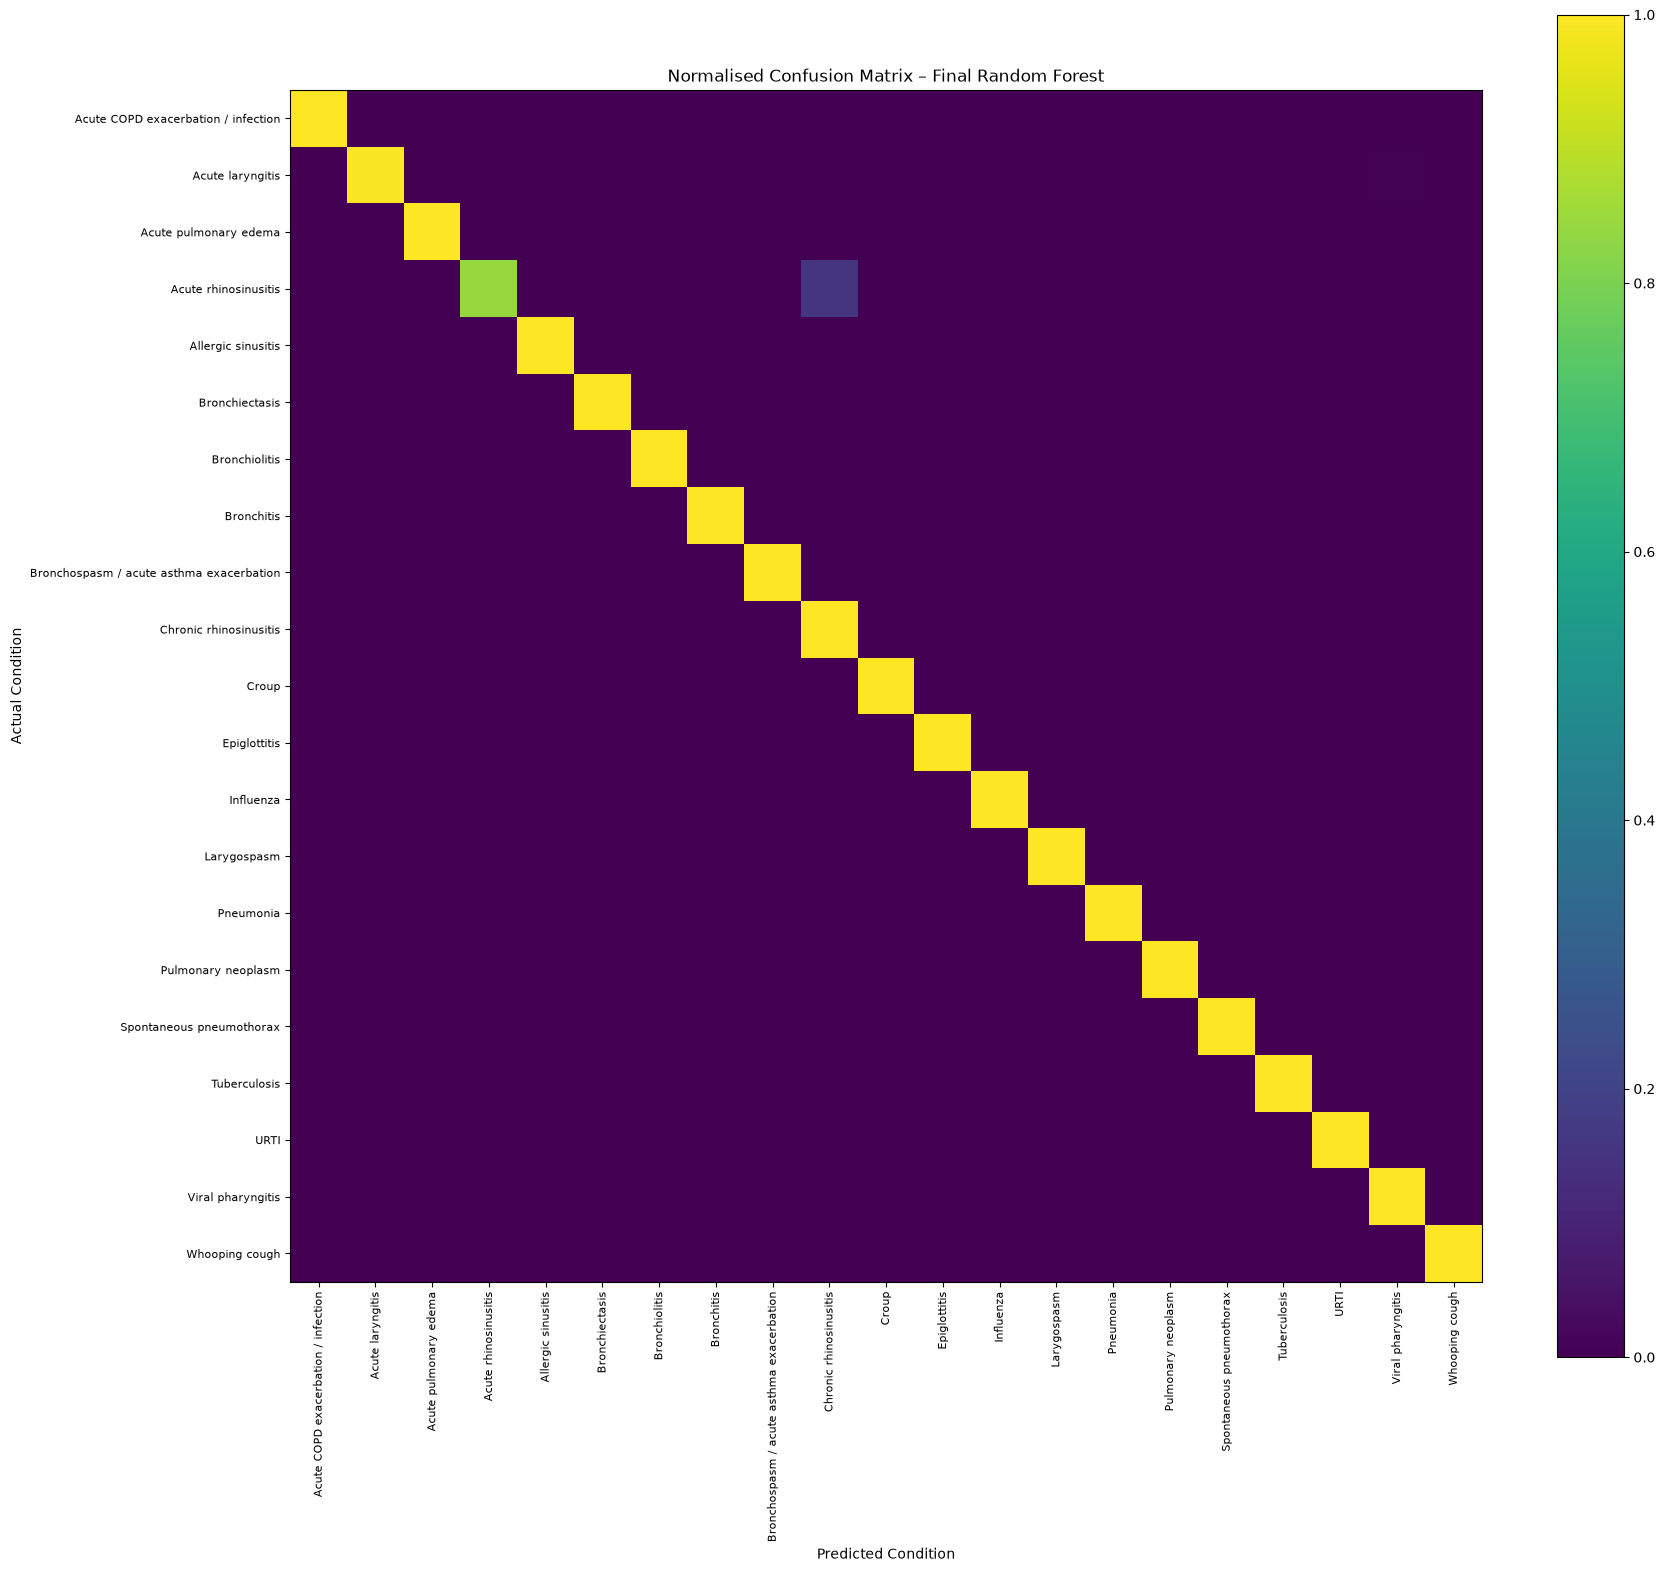

In [111]:
fig, ax = plt.subplots(
    figsize=(18, 16)
)

image = ax.imshow(
    test_cm_normalized
)

ax.set_xticks(
    np.arange(len(class_labels))
)

ax.set_yticks(
    np.arange(len(class_labels))
)

ax.set_xticklabels(
    class_labels,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    class_labels,
    fontsize=8
)

ax.set_xlabel(
    "Predicted Condition"
)

ax.set_ylabel(
    "Actual Condition"
)

ax.set_title(
    "Normalised Confusion Matrix – Final Random Forest"
)

fig.colorbar(
    image,
    ax=ax
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "final_random_forest_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [112]:
error_matrix = test_cm.copy()

np.fill_diagonal(
    error_matrix,
    0
)

error_records = []

for actual_index, actual_class in enumerate(
    class_labels
):

    for predicted_index, predicted_class in enumerate(
        class_labels
    ):

        count = error_matrix[
            actual_index,
            predicted_index
        ]

        if count > 0:

            error_records.append({
                "Actual": actual_class,
                "Predicted": predicted_class,
                "Count": int(count)
            })

confusion_errors_df = (
    pd.DataFrame(error_records)
    .sort_values(
        "Count",
        ascending=False
    )
    .reset_index(drop=True)
)

confusion_errors_df.head(15)

,Actual,Predicted,Count
0,Acute rhinosinusitis,Chronic rhinosinusitis,280
1,Acute laryngitis,Viral pharyngitis,23
2,Viral pharyngitis,Acute laryngitis,8
3,Chronic rhinosinusitis,Acute rhinosinusitis,6


In [113]:
confusion_errors_df.to_csv(
    METRICS_DIR
    / "final_random_forest_test_confusion_errors.csv",
    index=False
)

print(
    "Confusion error analysis saved."
)

Confusion error analysis saved.


### 11.1 Tuberculosis One-vs-Rest Confusion Matrix

For clearer presentation in the final report, a one-vs-rest confusion matrix was also generated for Tuberculosis. In this analysis, Tuberculosis is treated as the positive class, while all other respiratory conditions are grouped as the negative class.

This provides a simple 2 × 2 representation showing the True Positives, False Positives, False Negatives and True Negatives for Tuberculosis.

In [114]:
target_disease = "Tuberculosis"

tb_actual = (
    y_test == target_disease
)

tb_predicted = (
    test_predictions == target_disease
)

tb_cm = confusion_matrix(
    tb_actual,
    tb_predicted,
    labels=[False, True]
)

tn, fp, fn, tp = tb_cm.ravel()

print("Tuberculosis One-vs-Rest Results")
print("--------------------------------")
print("True Positives (TP):", tp)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Negatives (TN):", tn)

Tuberculosis One-vs-Rest Results
--------------------------------
True Positives (TP): 2080
False Positives (FP): 0
False Negatives (FN): 0
True Negatives (TN): 54737


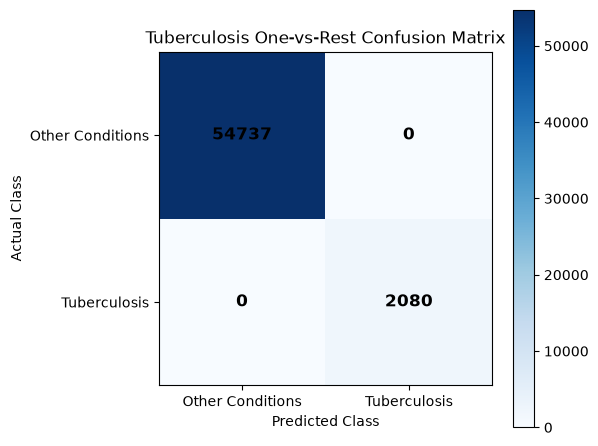

In [122]:
tb_display_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

fig, ax = plt.subplots(
    figsize=(6, 5)
)

image = ax.imshow(
    tb_display_matrix,
    cmap="Blues"
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Other Conditions",
    "Tuberculosis"
])

ax.set_yticklabels([
    "Other Conditions",
    "Tuberculosis"
])

ax.set_xlabel(
    "Predicted Class"
)

ax.set_ylabel(
    "Actual Class"
)

ax.set_title(
    "Tuberculosis One-vs-Rest Confusion Matrix"
)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            tb_display_matrix[i, j],
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold"
        )

fig.colorbar(
    image,
    ax=ax
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "tuberculosis_binary_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [123]:
tb_confusion_summary = pd.DataFrame({
    "Measure": [
        "True Positive (TP)",
        "False Positive (FP)",
        "False Negative (FN)",
        "True Negative (TN)"
    ],
    "Count": [
        tp,
        fp,
        fn,
        tn
    ]
})

tb_confusion_summary

,Measure,Count
0,True Positive (TP),2080
1,False Positive (FP),0
2,False Negative (FN),0
3,True Negative (TN),54737


In [124]:
tb_confusion_summary.to_csv(
    METRICS_DIR
    / "tuberculosis_binary_confusion_summary.csv",
    index=False
)

print(
    "Tuberculosis confusion matrix results saved."
)

Tuberculosis confusion matrix results saved.


### Tuberculosis Confusion Matrix Observation

The one-vs-rest confusion matrix shows the performance of the Random Forest model specifically for Tuberculosis. Tuberculosis cases are treated as the positive class, while all other conditions are treated as the negative class.

The model correctly identified the Tuberculosis cases in the test dataset and did not incorrectly classify other conditions as Tuberculosis. This is consistent with the precision, recall and F1-score of 1.000 obtained for Tuberculosis in the final classification report. These results describe performance on the available test dataset and should not be interpreted as evidence of perfect performance in real-world clinical use.

## 12. Random Forest Feature Importance

Feature importance was analysed to identify which input features contributed most strongly to the Random Forest model's predictions.

The Random Forest model provides impurity-based feature importance values for each input feature. These values indicate the relative contribution of each feature across the decision trees in the ensemble.

The feature importance analysis is used as a global interpretation of the model and is complemented later by SHAP analysis for more detailed explanations.

In [125]:
feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_model.feature_importances_
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Number of model features:",
    len(feature_importance_df)
)

feature_importance_df.head(20)

Number of model features: 198


,Feature,Importance
0,E_41,0.030273
1,E_57_@_V_123,0.024436
2,E_212,0.023059
3,E_56,0.022960
4,E_54_@_V_181,0.018643
5,E_55_@_V_33,0.018602
6,E_181,0.018341
7,E_123,0.018254
8,E_97,0.017561
9,E_77,0.016901


In [126]:
feature_importance_df.to_csv(
    METRICS_DIR
    / "random_forest_feature_importance.csv",
    index=False
)

print(
    "Feature importance results saved."
)

Feature importance results saved.


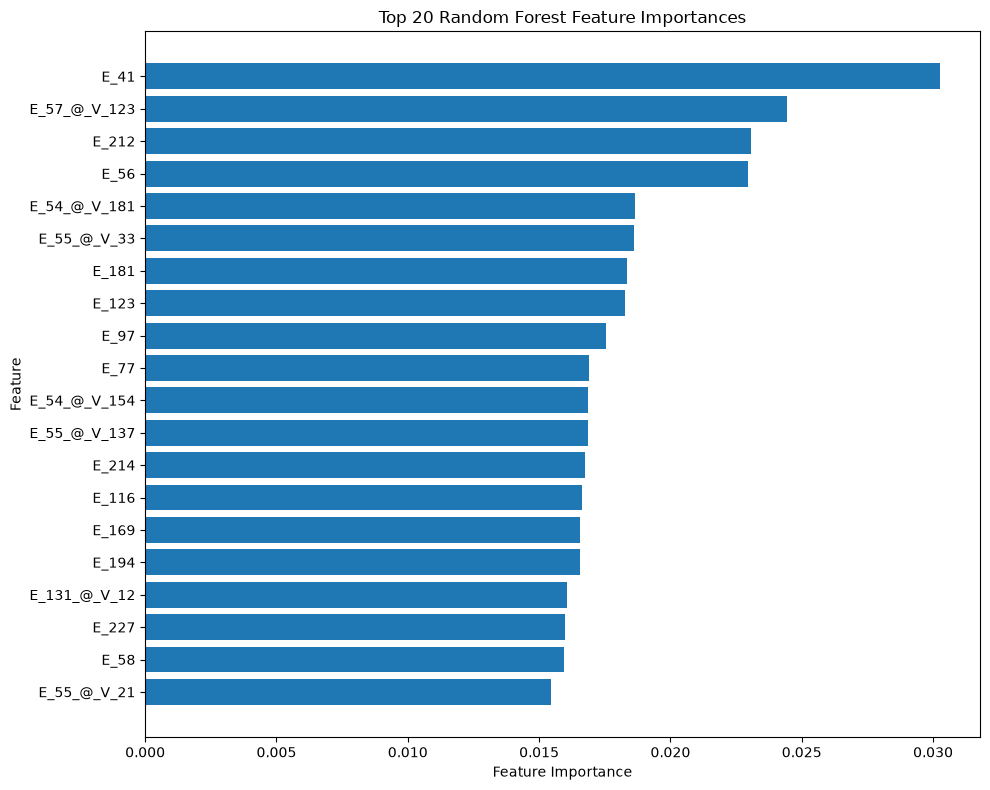

In [127]:
top_n = 20

top_features = (
    feature_importance_df
    .head(top_n)
    .sort_values(
        "Importance",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

ax.barh(
    top_features["Feature"],
    top_features["Importance"]
)

ax.set_xlabel(
    "Feature Importance"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "Top 20 Random Forest Feature Importances"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "random_forest_top20_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 12.1 Readable Feature Importance

The encoded DDXPlus feature identifiers were converted into their original English evidence descriptions using the DDXPlus evidence metadata. This makes the feature-importance results easier to interpret and present in the final report.

The original encoded feature names are retained alongside the readable descriptions so that the results remain traceable to the model input features.

In [128]:
RAW_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
)

with open(
    RAW_DIR / "release_evidences.json",
    "r",
    encoding="utf-8"
) as f:
    evidence_metadata = json.load(f)

print(
    "Evidence metadata loaded:",
    len(evidence_metadata)
)

Evidence metadata loaded: 223


In [129]:
def get_value_meaning(
    evidence_info,
    value
):

    value_meanings = (
        evidence_info.get(
            "value_meaning",
            {}
        )
    )

    meaning = value_meanings.get(
        value
    )

    if isinstance(
        meaning,
        dict
    ):
        return (
            meaning.get("en")
            or meaning.get("fr")
            or value
        )

    if isinstance(
        meaning,
        str
    ):
        return meaning

    return value

In [130]:
def feature_to_readable(
    feature
):

    if feature == "AGE":
        return "Age"

    if feature == "SEX_M":
        return "Sex: Male"

    if "_@_" in feature:

        evidence_code, value = (
            feature.split(
                "_@_",
                1
            )
        )

    else:

        evidence_code = feature
        value = None

    evidence_info = (
        evidence_metadata.get(
            evidence_code
        )
    )

    if evidence_info is None:
        return feature

    readable_name = (
        evidence_info.get(
            "question_en"
        )
        or evidence_info.get(
            "name"
        )
        or evidence_code
    )

    if value is not None:

        readable_value = (
            get_value_meaning(
                evidence_info,
                value
            )
        )

        readable_name = (
            f"{readable_name}: "
            f"{readable_value}"
        )

    return readable_name

In [131]:
readable_feature_importance_df = (
    feature_importance_df.copy()
)

readable_feature_importance_df[
    "Readable_Feature"
] = (
    readable_feature_importance_df[
        "Feature"
    ].apply(
        feature_to_readable
    )
)

readable_feature_importance_df[
    [
        "Feature",
        "Readable_Feature",
        "Importance"
    ]
].head(20)

,Feature,Readable_Feature,Importance
0,E_41,Have you been in contact with a person with si...,0.030273
1,E_57_@_V_123,Does the pain radiate to another location?: no...,0.024436
2,E_212,Have you noticed that the tone of your voice h...,0.023059
3,E_56,How intense is the pain?,0.022960
4,E_54_@_V_181,Characterize your pain:: burning,0.018643
5,E_55_@_V_33,Do you feel pain somewhere?: thyroid cartilage,0.018602
6,E_181,Do you have nasal congestion or a clear runny ...,0.018341
7,E_123,Do you have a chronic obstructive pulmonary di...,0.018254
8,E_97,Do you have a sore throat?,0.017561
9,E_77,Do you have a cough that produces colored or m...,0.016901


In [132]:
readable_feature_importance_df.to_csv(
    METRICS_DIR
    / "random_forest_feature_importance_readable.csv",
    index=False
)

print(
    "Readable feature importance saved."
)

Readable feature importance saved.


In [133]:
import textwrap

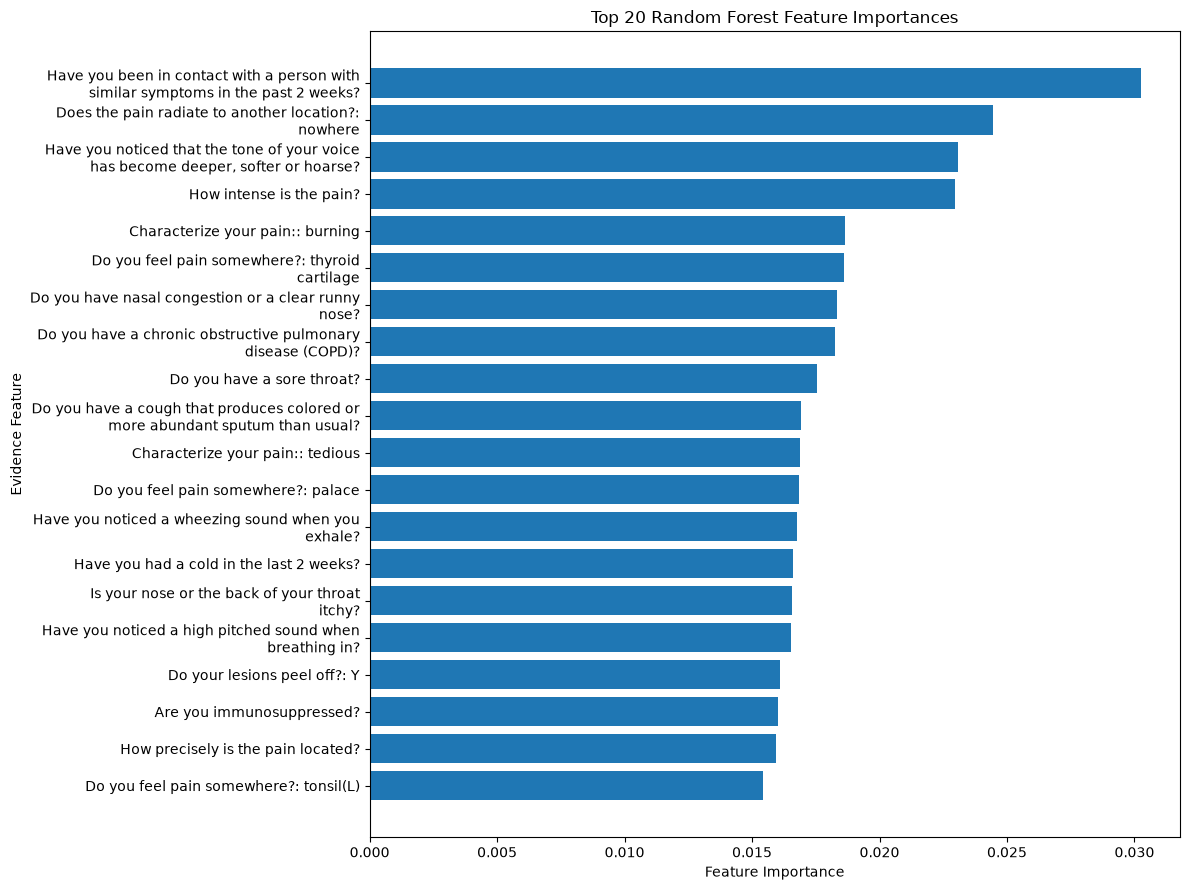

In [134]:
top_readable_features = (
    readable_feature_importance_df
    .head(20)
    .sort_values(
        "Importance",
        ascending=True
    )
    .copy()
)

top_readable_features[
    "Chart_Label"
] = (
    top_readable_features[
        "Readable_Feature"
    ].apply(
        lambda x:
        textwrap.fill(
            x,
            width=45
        )
    )
)

fig, ax = plt.subplots(
    figsize=(12, 9)
)

ax.barh(
    top_readable_features[
        "Chart_Label"
    ],
    top_readable_features[
        "Importance"
    ]
)

ax.set_xlabel(
    "Feature Importance"
)

ax.set_ylabel(
    "Evidence Feature"
)

ax.set_title(
    "Top 20 Random Forest Feature Importances"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "random_forest_top20_feature_importance_readable.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Feature Importance Observation

The feature-importance analysis showed that the Random Forest model relied on a mixture of respiratory symptoms, patient history and symptom characteristics. Important features included recent contact with a sick person, nasal congestion, sore throat, productive cough, wheezing, recent cold history and immunosuppression, together with several pain-related characteristics.

These importance values provide a global indication of which features were frequently useful to the Random Forest model. However, impurity-based feature importance does not show whether a feature increases or decreases a particular disease prediction. SHAP analysis was therefore used to provide more detailed model explanations.

## 13. SHAP Model Explainability

SHAP analysis was used to provide an additional interpretation of the final Random Forest model.

Unlike the built-in Random Forest feature importance, SHAP values estimate the contribution of individual input features to model predictions. Because the full test dataset is large, a stratified sample of test patients was used for the explainability analysis.

In [136]:
import shap

print(
    "SHAP version:",
    shap.__version__
)

c:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.51.0


In [137]:
shap_indices = []

for disease in final_model.classes_:

    disease_indices = (
        y_test[
            y_test == disease
        ].index
    )

    selected_indices = (
        pd.Series(
            disease_indices
        )
        .sample(
            n=min(
                5,
                len(disease_indices)
            ),
            random_state=42
        )
        .tolist()
    )

    shap_indices.extend(
        selected_indices
    )

X_shap = (
    X_test.loc[
        shap_indices
    ].copy()
)

y_shap = (
    y_test.loc[
        shap_indices
    ].copy()
)

print(
    "SHAP sample size:",
    len(X_shap)
)

print(
    "Diseases represented:",
    y_shap.nunique()
)

SHAP sample size: 105
Diseases represented: 21


In [138]:
shap_explainer = shap.TreeExplainer(
    final_model
)

print(
    "SHAP explainer created."
)

SHAP explainer created.


In [139]:
shap_values_raw = (
    shap_explainer.shap_values(
        X_shap,
        check_additivity=False
    )
)

print(
    "SHAP values calculated."
)

SHAP values calculated.


In [140]:
if isinstance(
    shap_values_raw,
    list
):

    shap_array = np.stack(
        shap_values_raw,
        axis=-1
    )

else:

    shap_array = np.asarray(
        shap_values_raw
    )

    if shap_array.ndim != 3:

        raise ValueError(
            "Unexpected SHAP array shape: "
            f"{shap_array.shape}"
        )

    if (
        shap_array.shape[0]
        == len(X_shap)
        and shap_array.shape[1]
        == X_shap.shape[1]
    ):

        pass

    elif (
        shap_array.shape[0]
        == len(X_shap)
        and shap_array.shape[2]
        == X_shap.shape[1]
    ):

        shap_array = np.transpose(
            shap_array,
            (0, 2, 1)
        )

    elif (
        shap_array.shape[0]
        == len(final_model.classes_)
        and shap_array.shape[1]
        == len(X_shap)
        and shap_array.shape[2]
        == X_shap.shape[1]
    ):

        shap_array = np.transpose(
            shap_array,
            (1, 2, 0)
        )

    else:

        raise ValueError(
            "Unable to interpret SHAP shape: "
            f"{shap_array.shape}"
        )

print(
    "Standardised SHAP shape:",
    shap_array.shape
)

Standardised SHAP shape: (105, 198, 21)


In [141]:
mean_absolute_shap = (
    np.abs(
        shap_array
    )
    .mean(
        axis=(0, 2)
    )
)

shap_importance_df = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": mean_absolute_shap
})

shap_importance_df[
    "Readable_Feature"
] = (
    shap_importance_df[
        "Feature"
    ].apply(
        feature_to_readable
    )
)

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

shap_importance_df.head(20)

,Feature,Mean_Absolute_SHAP,Readable_Feature
0,E_57_@_V_123,0.012398,Does the pain radiate to another location?: no...
1,E_56,0.008229,How intense is the pain?
2,E_58,0.006891,How precisely is the pain located?
3,E_53,0.006861,"Do you have pain somewhere, related to your re..."
4,E_41,0.005665,Have you been in contact with a person with si...
5,E_54_@_V_181,0.005147,Characterize your pain:: burning
6,E_181,0.004222,Do you have nasal congestion or a clear runny ...
7,E_214,0.004154,Have you noticed a wheezing sound when you exh...
8,E_77,0.004006,Do you have a cough that produces colored or m...
9,E_123,0.003948,Do you have a chronic obstructive pulmonary di...


In [142]:
shap_importance_df.to_csv(
    METRICS_DIR
    / "random_forest_global_shap_importance.csv",
    index=False
)

print(
    "Global SHAP importance saved."
)

Global SHAP importance saved.


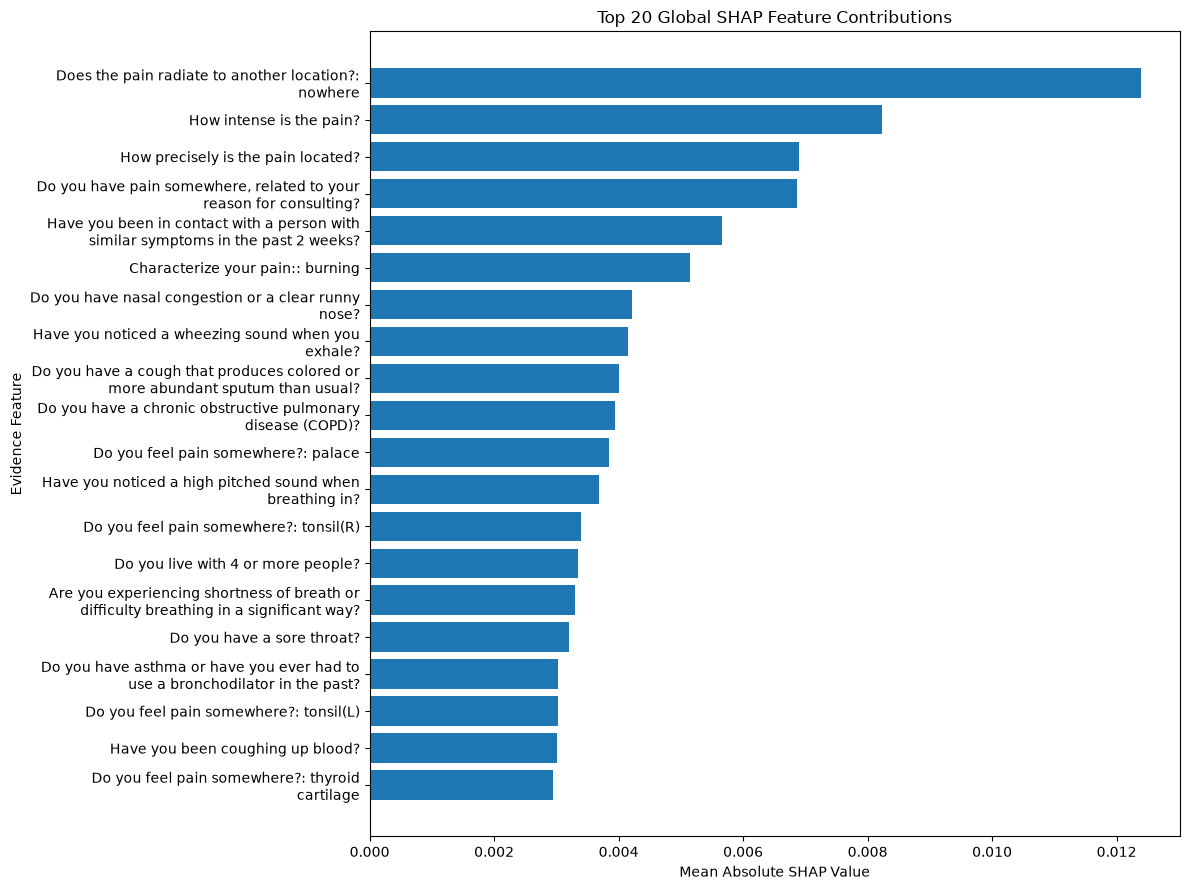

In [143]:
top_shap_features = (
    shap_importance_df
    .head(20)
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=True
    )
    .copy()
)

top_shap_features[
    "Chart_Label"
] = (
    top_shap_features[
        "Readable_Feature"
    ].apply(
        lambda x:
        textwrap.fill(
            x,
            width=45
        )
    )
)

fig, ax = plt.subplots(
    figsize=(12, 9)
)

ax.barh(
    top_shap_features[
        "Chart_Label"
    ],
    top_shap_features[
        "Mean_Absolute_SHAP"
    ]
)

ax.set_xlabel(
    "Mean Absolute SHAP Value"
)

ax.set_ylabel(
    "Evidence Feature"
)

ax.set_title(
    "Top 20 Global SHAP Feature Contributions"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "random_forest_top20_global_shap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Global SHAP Observation

The global SHAP analysis identified a combination of symptom characteristics, respiratory symptoms and patient history as important contributors to the Random Forest predictions. Features related to pain characteristics, contact with a sick person, nasal congestion, wheezing, productive cough, COPD history, shortness of breath, sore throat, asthma history and coughing up blood appeared among the stronger contributors.

The SHAP values represent the model's use of these features across the sampled test patients and should not be interpreted as clinical importance or causation.

### 13.1 Example Tuberculosis Prediction Explanation

A correctly classified Tuberculosis test case was selected to demonstrate how individual features contributed to a specific Random Forest prediction.

The example is intended to show how the model generated a prediction and does not represent a clinical explanation or diagnosis.

In [144]:
tb_class_name = "Tuberculosis"

tb_class_index = np.where(
    final_model.classes_ == tb_class_name
)[0][0]

tb_sample_positions = np.where(
    y_shap.to_numpy() == tb_class_name
)[0]

print(
    "Tuberculosis patients in SHAP sample:",
    len(tb_sample_positions)
)

print(
    "Tuberculosis class index:",
    tb_class_index
)

Tuberculosis patients in SHAP sample: 5
Tuberculosis class index: 17


In [145]:
tb_sample_probabilities = (
    final_model.predict_proba(
        X_shap.iloc[tb_sample_positions]
    )[:, tb_class_index]
)

best_tb_position = (
    tb_sample_positions[
        np.argmax(
            tb_sample_probabilities
        )
    ]
)

tb_patient = (
    X_shap.iloc[
        [best_tb_position]
    ]
)

tb_actual_class = (
    y_shap.iloc[
        best_tb_position
    ]
)

tb_predicted_class = (
    final_model.predict(
        tb_patient
    )[0]
)

tb_probability = (
    final_model.predict_proba(
        tb_patient
    )[0, tb_class_index]
)

print(
    "Actual condition:",
    tb_actual_class
)

print(
    "Predicted condition:",
    tb_predicted_class
)

print(
    "Tuberculosis probability:",
    round(
        tb_probability,
        4
    )
)

Actual condition: Tuberculosis
Predicted condition: Tuberculosis
Tuberculosis probability: 1.0


In [146]:
tb_shap_values = (
    shap_array[
        best_tb_position,
        :,
        tb_class_index
    ]
)

tb_local_explanation = pd.DataFrame({
    "Feature": X_shap.columns,
    "Feature_Value": (
        X_shap.iloc[
            best_tb_position
        ].values
    ),
    "SHAP_Contribution": tb_shap_values
})

tb_local_explanation[
    "Readable_Feature"
] = (
    tb_local_explanation[
        "Feature"
    ].apply(
        feature_to_readable
    )
)

tb_local_explanation[
    "Absolute_SHAP"
] = (
    tb_local_explanation[
        "SHAP_Contribution"
    ].abs()
)

tb_local_explanation = (
    tb_local_explanation
    .sort_values(
        "Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

tb_local_explanation[
    [
        "Readable_Feature",
        "Feature_Value",
        "SHAP_Contribution"
    ]
].head(15)

,Readable_Feature,Feature_Value,SHAP_Contribution
0,Does the pain radiate to another location?: no...,0.0,0.064755
1,"Do you have pain somewhere, related to your re...",0.0,0.061831
2,How intense is the pain?,0.0,0.061357
3,How precisely is the pain located?,0.0,0.056469
4,Do you have diabetes?,1.0,0.039528
5,"Is your BMI less than 18.5, or are you underwe...",1.0,0.035892
6,Do you have a cough that produces colored or m...,0.0,0.023816
7,Have you noticed a wheezing sound when you exh...,0.0,0.023510
8,Do you have a cough?,1.0,0.022922
9,Have you been coughing up blood?,1.0,0.022556


In [147]:
tb_local_explanation.to_csv(
    METRICS_DIR
    / "tuberculosis_example_shap_explanation.csv",
    index=False
)

print(
    "Tuberculosis SHAP explanation saved."
)

Tuberculosis SHAP explanation saved.


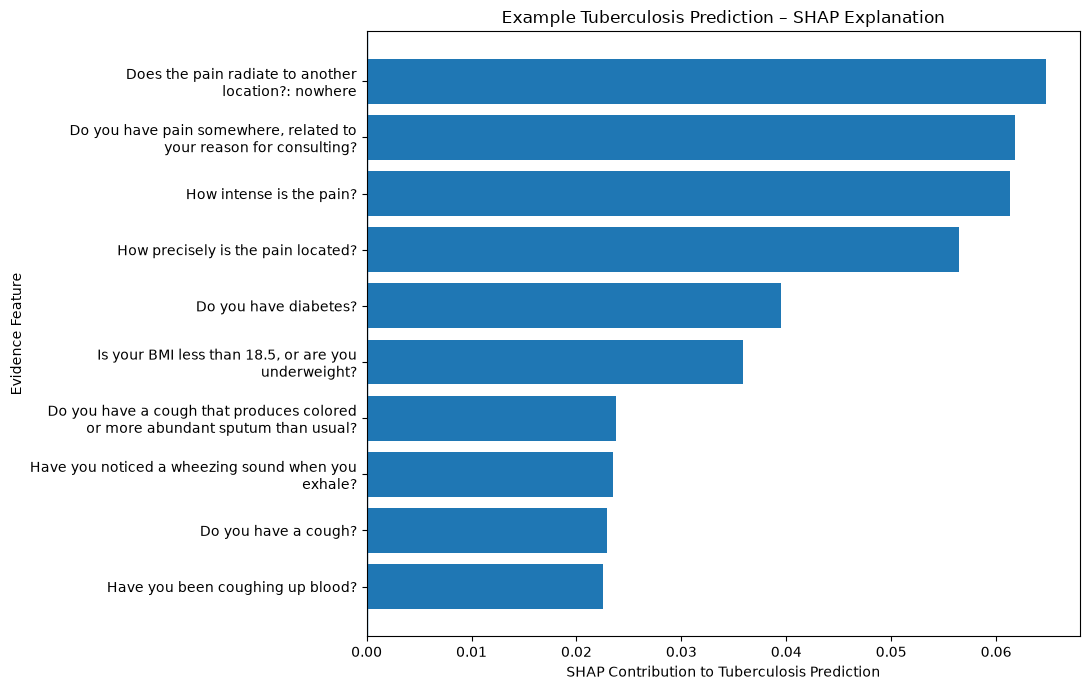

In [148]:
tb_top_shap = (
    tb_local_explanation
    .head(10)
    .sort_values(
        "SHAP_Contribution",
        ascending=True
    )
    .copy()
)

tb_top_shap[
    "Chart_Label"
] = (
    tb_top_shap[
        "Readable_Feature"
    ].apply(
        lambda x:
        textwrap.fill(
            x,
            width=42
        )
    )
)

fig, ax = plt.subplots(
    figsize=(11, 7)
)

ax.barh(
    tb_top_shap[
        "Chart_Label"
    ],
    tb_top_shap[
        "SHAP_Contribution"
    ]
)

ax.axvline(
    0,
    linewidth=1
)

ax.set_xlabel(
    "SHAP Contribution to Tuberculosis Prediction"
)

ax.set_ylabel(
    "Evidence Feature"
)

ax.set_title(
    "Example Tuberculosis Prediction – SHAP Explanation"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "tuberculosis_example_shap_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Tuberculosis SHAP Observation

The selected test case was correctly classified as Tuberculosis by the Random Forest model. The SHAP explanation showed that the prediction was influenced by a combination of present symptoms, patient history and the absence of other competing symptom patterns.

Features contributing to this particular prediction included cough, coughing up blood, low BMI or underweight status, diabetes and corticosteroid use, together with several other symptom characteristics. These contributions explain how the model reached this specific prediction and should not be interpreted as clinical evidence of causation.

## 14. Save Final Production Model and Metadata

The final tuned Random Forest model was saved together with the feature ordering, disease classes and model metadata required for later backend integration.

The saved metadata ensures that the backend can reproduce the same feature ordering used during model training.

In [149]:
final_model_path = (
    MODELS_DIR
    / "respiratory_random_forest_v1.joblib"
)

joblib.dump(
    final_model,
    final_model_path,
    compress=("xz", 3)
)

final_model_size_mb = (
    final_model_path.stat().st_size
    / (1024 ** 2)
)

print(
    "Final model saved to:",
    final_model_path
)

print(
    "Final model size:",
    round(final_model_size_mb, 2),
    "MB"
)

Final model saved to: ..\models\respiratory_random_forest_v1.joblib
Final model size: 52.78 MB


In [150]:
loaded_final_model = joblib.load(
    final_model_path
)

reload_predictions = (
    loaded_final_model.predict(
        X_test.iloc[:100]
    )
)

original_predictions = (
    final_model.predict(
        X_test.iloc[:100]
    )
)

print(
    "Reloaded model predictions match:",
    np.array_equal(
        reload_predictions,
        original_predictions
    )
)

print(
    "Reloaded model classes:",
    len(
        loaded_final_model.classes_
    )
)

Reloaded model predictions match: True
Reloaded model classes: 21


In [151]:
disease_classes = (
    final_model.classes_.tolist()
)

with open(
    MODELS_DIR
    / "disease_classes.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        disease_classes,
        f,
        indent=2
    )

print(
    "Disease classes saved:",
    len(disease_classes)
)

Disease classes saved: 21


In [152]:
final_model_metadata = {
    "model_name": "Random Forest",
    "model_version": "1.0",
    "purpose": (
        "Respiratory health awareness "
        "and prediction system"
    ),

    "number_of_diseases": int(
        len(final_model.classes_)
    ),

    "number_of_model_features": int(
        len(X_train.columns)
    ),

    "training_samples": int(
        len(X_train)
    ),

    "validation_samples": int(
        len(X_validate)
    ),

    "test_samples": int(
        len(X_test)
    ),

    "random_state": 42,

    "model_parameters": {
        "n_estimators": int(
            final_model.n_estimators
        ),
        "max_depth": (
            None
            if final_model.max_depth is None
            else int(final_model.max_depth)
        ),
        "min_samples_leaf": int(
            final_model.min_samples_leaf
        ),
        "class_weight": (
            final_model.class_weight
        )
    },

    "validation_metrics": {
        "accuracy": float(
            best_rf_validation_results[
                "Accuracy"
            ]
        ),
        "macro_precision": float(
            best_rf_validation_results[
                "Macro_Precision"
            ]
        ),
        "macro_recall": float(
            best_rf_validation_results[
                "Macro_Recall"
            ]
        ),
        "macro_f1": float(
            best_rf_validation_results[
                "Macro_F1"
            ]
        ),
        "weighted_f1": float(
            best_rf_validation_results[
                "Weighted_F1"
            ]
        ),
        "top3_accuracy": float(
            best_rf_top3
        ),
        "log_loss": float(
            best_rf_log_loss
        )
    },

    "test_metrics": {
        "accuracy": float(
            final_test_results[
                "Accuracy"
            ]
        ),
        "macro_precision": float(
            final_test_results[
                "Macro_Precision"
            ]
        ),
        "macro_recall": float(
            final_test_results[
                "Macro_Recall"
            ]
        ),
        "macro_f1": float(
            final_test_results[
                "Macro_F1"
            ]
        ),
        "weighted_f1": float(
            final_test_results[
                "Weighted_F1"
            ]
        ),
        "top3_accuracy": float(
            test_top3_accuracy
        ),
        "log_loss": float(
            test_log_loss
        )
    },

    "model_file": (
        final_model_path.name
    ),

    "model_size_mb": float(
        final_model_size_mb
    )
}

In [153]:
with open(
    MODELS_DIR
    / "model_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_model_metadata,
        f,
        indent=2
    )

print(
    "Final model metadata saved."
)

Final model metadata saved.


In [154]:
print("Final ML artifacts")
print("------------------")

for path in [
    MODELS_DIR / "model_features.json",
    MODELS_DIR / "disease_classes.json",
    MODELS_DIR / "model_metadata.json",
    final_model_path
]:

    print(
        path.name,
        "->",
        path.exists()
    )

Final ML artifacts
------------------
model_features.json -> True
disease_classes.json -> True
model_metadata.json -> True
respiratory_random_forest_v1.joblib -> True


## 15. Final Model Development Summary

The machine-learning development phase produced a Random Forest classifier for the respiratory health-awareness system using the prepared DDXPlus respiratory dataset.

The final model was trained using 198 active model features and supported 21 respiratory-related conditions. Random Forest and XGBoost were both evaluated and tuned using the validation dataset. XGBoost achieved slightly higher validation performance, while Random Forest remained highly competitive and was retained as the primary classifier for the proposed system.

The final Random Forest model achieved an accuracy of 0.994421, a Macro F1-score of 0.993296 and a Top-3 accuracy of 1.000 on the untouched test dataset. All 21 conditions were represented in the final predictions.

Feature importance and SHAP analysis were used to examine the model's behaviour. A Tuberculosis example was also analysed using a one-vs-rest confusion matrix and patient-level SHAP explanation.

The final trained model, ordered feature list, disease classes and model metadata were saved for later integration with the backend prediction service.

In [155]:
print("FINAL ML DEVELOPMENT CHECK")
print("--------------------------")

print(
    "Model:",
    final_model_name
)

print(
    "Diseases:",
    len(final_model.classes_)
)

print(
    "Model features:",
    len(X_train.columns)
)

print(
    "Test accuracy:",
    round(
        final_test_results["Accuracy"],
        6
    )
)

print(
    "Test Macro F1:",
    round(
        final_test_results["Macro_F1"],
        6
    )
)

print(
    "Test Top-3 accuracy:",
    round(
        test_top3_accuracy,
        6
    )
)

print(
    "Saved model size:",
    round(
        final_model_size_mb,
        2
    ),
    "MB"
)

print(
    "Saved model reload verified:",
    np.array_equal(
        reload_predictions,
        original_predictions
    )
)

FINAL ML DEVELOPMENT CHECK
--------------------------
Model: Random Forest
Diseases: 21
Model features: 198
Test accuracy: 0.994421
Test Macro F1: 0.993296
Test Top-3 accuracy: 1.0
Saved model size: 52.78 MB
Saved model reload verified: True
